<a href="https://colab.research.google.com/github/Saransh-Basu-01/Understanding-Deep-learning-/blob/main/Chapter_10_Convolutions_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 10.1: 1D Convolution

In [1]:
import numpy as np
import matplotlib.pyplot as plt


In [2]:
x = [5.2, 5.3, 5.4, 5.1, 10.1, 10.3, 9.9, 10.3, 3.2, 3.4, 3.3, 3.1]

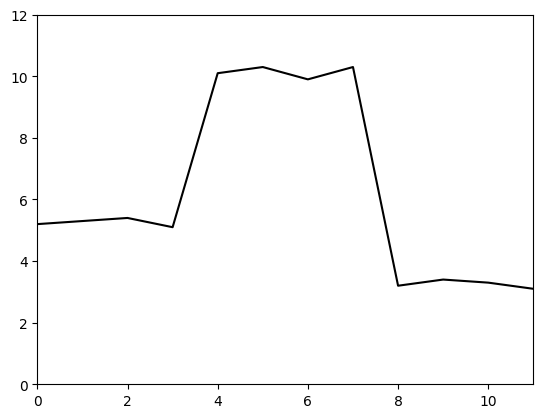

In [5]:
fig,ax=plt.subplots()
ax.plot(x,'k-')
ax.set_xlim(0,11)
ax.set_ylim(0,12)
plt.show()

In [6]:

# Now let's define a zero-padded convolution operation
# with a convolution kernel size of 3, a stride of 1, and a dilation of 1
# as in figure 10.2a-c.  Write it yourself, don't call a library routine!
# Don't forget that Python arrays are indexed from zero, not from 1 as in the book figures
def conv_3_1_1_zp(x_in, omega):
    x_out = np.zeros_like(x_in)
    n = len(x_in)
    for i in range(n):
        acc = 0.0
        for k in range(3):
            j = i + k - 1          # offset by -1 so k=0 -> i-1, k=1 -> i, k=2 -> i+1
            if 0 <= j < n:         # zero-padding: skip out-of-range indices
                acc += omega[k] * x_in[j]
        x_out[i] = acc
    return x_out

- low pass filtering using convolution

Sum of output is 71.1, should be 71.1


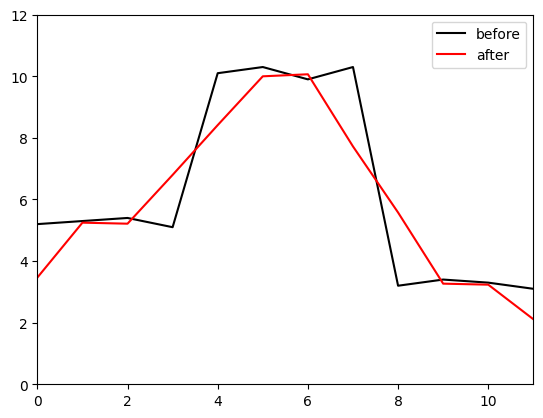

In [7]:


omega = [0.33,0.33,0.33]
h = conv_3_1_1_zp(x, omega)

# Check that you have computed this correctly
print(f"Sum of output is {np.sum(h):3.3}, should be 71.1")

# Draw the signal
fig,ax = plt.subplots()
ax.plot(x, 'k-',label='before')
ax.plot(h, 'r-',label='after')
ax.set_xlim(0,11)
ax.set_ylim(0, 12)
ax.legend()
plt.show()

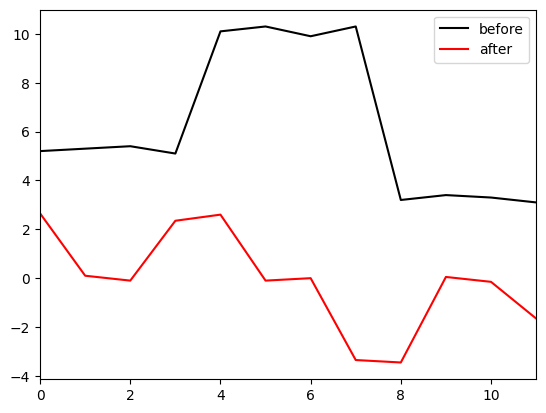

In [10]:
omega = [-0.5,0,0.5]
h2 = conv_3_1_1_zp(x, omega)

# Draw the signal
fig,ax = plt.subplots()
ax.plot(x, 'k-',label='before')
ax.plot(h2, 'r-',label='after')
ax.set_xlim(0,11)
# ax.set_ylim(0, 12)
ax.legend()
plt.show()


In [15]:
def conv_3_2_1_zp(x_in, omega):
    # Output length is ceil(len/2). We use integer division (//) to loop over it.
    out_len = int(np.ceil(len(x_in) / 2))
    x_out = np.zeros(out_len)

    n_in = len(x_in) # The actual length of the input array

    for i in range(out_len):
        acc = 0.0
        for k in range(3):
            # Because stride=2, we multiply i by 2.
            # The index j = 2*i + k - 1 is mathematically correct!
            j = 2*i + k - 1

            # Check against the FULL input length
            if 0 <= j < n_in:
                acc += omega[k] * x_in[j]

        x_out[i] = acc
    return x_out

In [16]:
omega = [0.33,0.33,0.33]
h3 = conv_3_2_1_zp(x, omega)

# If you have done this right, the output length should be six and it should
# contain every other value from the original convolution with stride 1
print(h)
print(h3)

[ 3.465  5.247  5.214  6.798  8.415  9.999 10.065  7.722  5.577  3.267
  3.234  2.112]
[ 3.465  5.214  8.415 10.065  5.577  3.234]


In [21]:


# Now let's define a zero-padded convolution operation
# with a convolution kernel size of 5, a stride of 1, and a dilation of 1
# as in figure 10.3c.  Write it yourself, don't call a library routine!
def conv_5_1_1_zp(x_in, omega):
    x_out = np.zeros_like(x_in)
    # TODO -- write this function
    # replace this line
    x_out = np.zeros_like(x_in)
    n = len(x_in)
    for i in range(n):
        acc = 0.0
        for k in range(5):
            j = i + k - 2
            if 0 <= j < n:
                acc += omega[k] * x_in[j]
        x_out[i] = acc
    return x_out

Sum of output is 69.6, should be 69.6


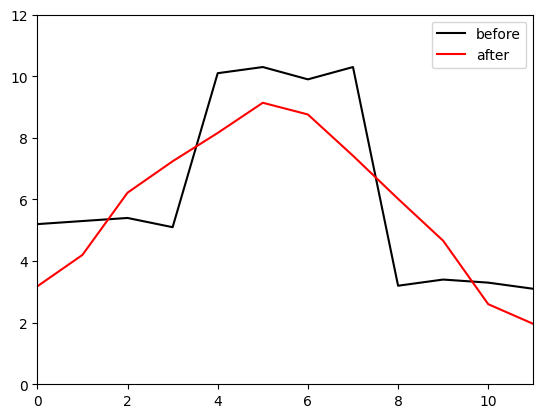

In [22]:
omega2 = [0.2, 0.2, 0.2, 0.2, 0.2]
h4 = conv_5_1_1_zp(x, omega2)

# Check that you have computed this correctly
print(f"Sum of output is {np.sum(h4):3.3}, should be 69.6")

# Draw the signal
fig,ax = plt.subplots()
ax.plot(x, 'k-',label='before')
ax.plot(h4, 'r-',label='after')
ax.set_xlim(0,11)
ax.set_ylim(0, 12)
ax.legend()
plt.show()

In [25]:


# Finally let's define a zero-padded convolution operation
# with a convolution kernel size of 3, a stride of 1, and a dilation of 2
# as in figure 10.3d.  Write it yourself, don't call a library routine!
# Don't forget that Python arrays are indexed from zero, not from 1 as in the book figures
def conv_3_1_2_zp(x_in, omega):
    x_out = np.zeros_like(x_in)
    # TODO -- write this function
    # replace this line
    x_out = np.zeros_like(x_in)
    n = len(x_in)
    for i in range(n):
        acc = 0.0
        for k in range(3):
            j = i + 2* (k - 1)
            if 0 <= j < n:
                acc += omega[k] * x_in[j]
        x_out[i] = acc
    return x_out

Sum of output is 68.3, should be 68.3


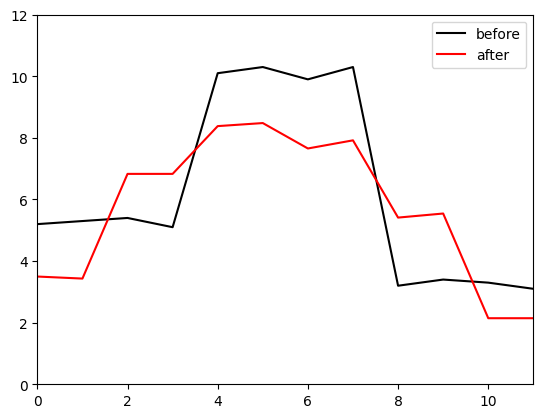

In [26]:

omega = [0.33,0.33,0.33]
h5 = conv_3_1_2_zp(x, omega)

# Check that you have computed this correctly
print(f"Sum of output is {np.sum(h5):3.3}, should be 68.3")

# Draw the signal
fig,ax = plt.subplots()
ax.plot(x, 'k-',label='before')
ax.plot(h5, 'r-',label='after')
ax.set_xlim(0,11)
ax.set_ylim(0, 12)
ax.legend()
plt.show()

In [27]:
import numpy as np

def get_conv_mat_3_1_1_zp(n_out, omega):
    omega_mat = np.zeros((n_out, n_out))

    for i in range(n_out):
        for k in range(3):
            j = i + k - 1          # The same offset logic: k=0 -> i-1, k=1 -> i, k=2 -> i+1
            if 0 <= j < n_out:     # Zero-padding boundary check
                omega_mat[i, j] = omega[k]

    return omega_mat

In [28]:
# Run original convolution
omega = np.array([-1.0,0.5,-0.2])
h6 = conv_3_1_1_zp(x, omega)
print(h6)

# If you have done this right, you should get the same answer
omega_mat = get_conv_mat_3_1_1_zp(len(x), omega)
h7 = np.matmul(omega_mat, x)
print(h7)

[ 1.54 -3.63 -3.62 -4.87 -2.11 -6.93 -7.41 -5.39 -9.38 -2.16 -2.37 -1.75]
[ 1.54 -3.63 -3.62 -4.87 -2.11 -6.93 -7.41 -5.39 -9.38 -2.16 -2.37 -1.75]


# Notebook 10.2: Convolution for MNIST-1D

In [29]:


# Run this if you're in a Colab to install MNIST 1D repository
!pip install git+https://github.com/greydanus/mnist1d

  Cloning https://github.com/greydanus/mnist1d to /tmp/pip-req-build-j6tgu63n
  Running command git clone --filter=blob:none --quiet https://github.com/greydanus/mnist1d /tmp/pip-req-build-j6tgu63n
  Resolved https://github.com/greydanus/mnist1d to commit e2f536fa86442c13473b433d579e9852ec4d1c1d
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for mnist1d: filename=mnist1d-0.0.2.post23-py3-none-any.whl size=14666 sha256=bbfc84e880620a9fe3f82452582a41af177df3973fab7b92e2ee1e73710d63b0
  Stored in directory: /tmp/pip-ephem-wheel-cache-vj0ofucb/wheels/33/99/c5/794fea38f039adfbca82fd56e4a00b3e1e4533a808baee9910
Successfully built mnist1d


In [30]:

import numpy as np
import os
import torch, torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from torch.optim.lr_scheduler import StepLR
import matplotlib.pyplot as plt
import mnist1d
import random

In [31]:
args = mnist1d.data.get_dataset_args()
data = mnist1d.data.get_dataset(args, path='./mnist1d_data.pkl', download=False, regenerate=False)

# The training and test input and outputs are in
# data['x'], data['y'], data['x_test'], and data['y_test']
print("Examples in training set: {}".format(len(data['y'])))
print("Examples in test set: {}".format(len(data['y_test'])))
print("Length of each example: {}".format(data['x'].shape[-1]))

Did or could not load data from ./mnist1d_data.pkl. Rebuilding dataset...
Examples in training set: 4000
Examples in test set: 1000
Length of each example: 40


In [32]:
# Load in the data
train_data_x = data['x'].transpose()
train_data_y = data['y']
val_data_x = data['x_test'].transpose()
val_data_y = data['y_test']
# Print out sizes
print("Train data: %d examples (columns), each of which has %d dimensions (rows)"%((train_data_x.shape[1],train_data_x.shape[0])))
print("Validation data: %d examples (columns), each of which has %d dimensions (rows)"%((val_data_x.shape[1],val_data_x.shape[0])))


Train data: 4000 examples (columns), each of which has 40 dimensions (rows)
Validation data: 1000 examples (columns), each of which has 40 dimensions (rows)


In [33]:

# There are 40 input dimensions and 10 output dimensions for this data
# The inputs correspond to the 40 offsets in the MNIST1D template.
D_i = 40
# The outputs correspond to the 10 digits
D_o = 10


# TODO Create a model with the following layers
# 1. Convolutional layer, (input=length 40 and 1 channel, kernel size 3, stride 2, padding="valid", 15 output channels )
# 2. ReLU
# 3. Convolutional layer, (input=length 19 and 15 channels, kernel size 3, stride 2, padding="valid", 15 output channels )
# 4. ReLU
# 5. Convolutional layer, (input=length 9 and 15 channels, kernel size 3, stride 2, padding="valid", 15 output channels)
# 6. ReLU
# 7. Flatten (converts 4x15) to length 60
# 8. Linear layer (input size = 60, output size = 10)
# References:
# https://pytorch.org/docs/1.13/generated/torch.nn.Conv1d.html?highlight=conv1d#torch.nn.Conv1d
# https://pytorch.org/docs/stable/generated/torch.nn.Flatten.html
# https://pytorch.org/docs/1.13/generated/torch.nn.Linear.html?highlight=linear#torch.nn.Linear

# NOTE THAT THE CONVOLUTIONAL LAYERS NEED TO TAKE THE NUMBER OF INPUT CHANNELS AS A PARAMETER
# AND NOT THE INPUT SIZE.

# Replace the following function:
model = nn.Sequential(
    # 1. Conv1d: input=1 channel, 15 output channels, kernel=3, stride=2, valid padding
    nn.Conv1d(in_channels=1, out_channels=15, kernel_size=3, stride=2, padding="valid"),
    # 2. ReLU
    nn.ReLU(),

    # 3. Conv1d: input=15 channels, 15 output channels, kernel=3, stride=2, valid padding
    nn.Conv1d(in_channels=15, out_channels=15, kernel_size=3, stride=2, padding="valid"),
    # 4. ReLU
    nn.ReLU(),

    # 5. Conv1d: input=15 channels, 15 output channels, kernel=3, stride=2, valid padding
    nn.Conv1d(in_channels=15, out_channels=15, kernel_size=3, stride=2, padding="valid"),
    # 6. ReLU
    nn.ReLU(),

    # 7. Flatten: converts the (15 channels x 4 length) tensor into a flat vector of size 60
    nn.Flatten(),

    # 8. Linear: input=60, output=10
    nn.Linear(in_features=60, out_features=10)
)


In [34]:
# He initialization of weights
def weights_init(layer_in):
  if isinstance(layer_in, nn.Linear):
    nn.init.kaiming_uniform_(layer_in.weight)
    layer_in.bias.data.fill_(0.0)

Epoch     0, train loss 2.222642, train error 80.05,  val loss 2.231860, percent error 81.40
Epoch     1, train loss 1.607593, train error 64.30,  val loss 1.618101, percent error 66.30
Epoch     2, train loss 1.436962, train error 59.55,  val loss 1.449923, percent error 59.60
Epoch     3, train loss 1.341224, train error 54.33,  val loss 1.365944, percent error 56.30
Epoch     4, train loss 1.214389, train error 49.42,  val loss 1.238469, percent error 51.80
Epoch     5, train loss 1.157208, train error 46.83,  val loss 1.145562, percent error 47.60
Epoch     6, train loss 1.044060, train error 40.35,  val loss 1.064397, percent error 41.10
Epoch     7, train loss 0.936317, train error 37.08,  val loss 0.963777, percent error 37.90
Epoch     8, train loss 0.813950, train error 31.20,  val loss 0.867412, percent error 34.30
Epoch     9, train loss 0.791336, train error 29.10,  val loss 0.820210, percent error 30.90
Epoch    10, train loss 0.632315, train error 23.85,  val loss 0.67897

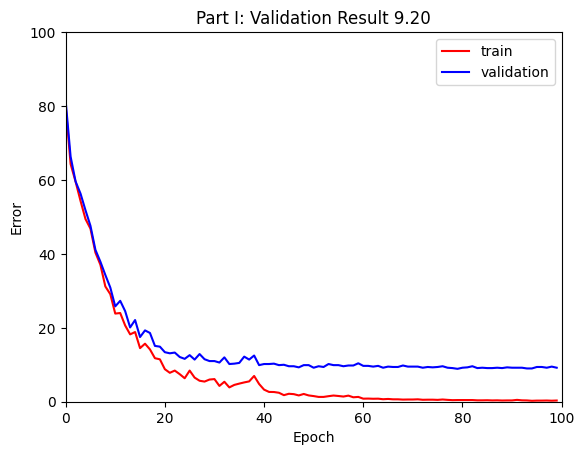

In [35]:

# choose cross entropy loss function (equation 5.24 in the loss notes)
loss_function = nn.CrossEntropyLoss()
# construct SGD optimizer and initialize learning rate and momentum
optimizer = torch.optim.SGD(model.parameters(), lr = 0.05, momentum=0.9)
# object that decreases learning rate by half every 20 epochs
scheduler = StepLR(optimizer, step_size=20, gamma=0.5)
# create 100 dummy data points and store in data loader class
x_train = torch.tensor(train_data_x.transpose().astype('float32'))
y_train = torch.tensor(train_data_y.astype('long')).long()
x_val= torch.tensor(val_data_x.transpose().astype('float32'))
y_val = torch.tensor(val_data_y.astype('long')).long()

# load the data into a class that creates the batches
data_loader = DataLoader(TensorDataset(x_train,y_train), batch_size=100, shuffle=True, worker_init_fn=np.random.seed(1))

# Initialize model weights
model.apply(weights_init)

# loop over the dataset n_epoch times
n_epoch = 100
# store the loss and the % correct at each epoch
losses_train = np.zeros((n_epoch))
errors_train = np.zeros((n_epoch))
losses_val = np.zeros((n_epoch))
errors_val = np.zeros((n_epoch))

for epoch in range(n_epoch):
  # loop over batches
  for i, data in enumerate(data_loader):
    # retrieve inputs and labels for this batch
    x_batch, y_batch = data
    # zero the parameter gradients
    optimizer.zero_grad()
    # forward pass -- calculate model output
    pred = model(x_batch[:,None,:])
    # compute the loss
    loss = loss_function(pred, y_batch)
    # backward pass
    loss.backward()
    # SGD update
    optimizer.step()

  # Run whole dataset to get statistics -- normally wouldn't do this
  pred_train = model(x_train[:,None,:])
  pred_val = model(x_val[:,None,:])
  _, predicted_train_class = torch.max(pred_train.data, 1)
  _, predicted_val_class = torch.max(pred_val.data, 1)
  errors_train[epoch] = 100 - 100 * (predicted_train_class == y_train).float().sum() / len(y_train)
  errors_val[epoch]= 100 - 100 * (predicted_val_class == y_val).float().sum() / len(y_val)
  losses_train[epoch] = loss_function(pred_train, y_train).item()
  losses_val[epoch]= loss_function(pred_val, y_val).item()
  print(f'Epoch {epoch:5d}, train loss {losses_train[epoch]:.6f}, train error {errors_train[epoch]:3.2f},  val loss {losses_val[epoch]:.6f}, percent error {errors_val[epoch]:3.2f}')

  # tell scheduler to consider updating learning rate
  scheduler.step()

# Plot the results
fig, ax = plt.subplots()
ax.plot(errors_train,'r-',label='train')
ax.plot(errors_val,'b-',label='validation')
ax.set_ylim(0,100); ax.set_xlim(0,n_epoch)
ax.set_xlabel('Epoch'); ax.set_ylabel('Error')
ax.set_title('Part I: Validation Result %3.2f'%(errors_val[-1]))
ax.legend()
plt.show()